In [2]:
import sys
print(sys.executable)

/Users/alitura/Downloads/Turakhan_ML_task_2/.Turakhan_ML_task_2/bin/python


In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [4]:
SEED = 2495

data = pd.read_csv("heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


In [5]:
data.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,disease
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2,3,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0,3,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1,7,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0,7,1


In [ ]:
# task 1
toy = pd.DataFrame({
    "age_55_plus": [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male": [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp": [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease": [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})

def h(labels):
    n = len(labels)
    total = 0.0
    for c in [0, 1]:
        p = (labels == c).sum() / n
        if p > 0:
            total = total - p * np.log2(p)
    return total

n = len(toy)
p1 = (toy["disease"] == 1).sum() / n
p0 = (toy["disease"] == 0).sum() / n
print("p1 =", p1, "p0 =", p0)
print("H =", -p1, "* log2(", p1, ") -", p0, "* log2(", p0, ") =", h(toy["disease"]))

p1 = 0.5 p0 = 0.5
H = -0.5 * log2( 0.5 ) - 0.5 * log2( 0.5 ) = 1.0


In [8]:
def show_gain(df, feature):
    parent = h(df["disease"])
    left = df[df[feature] == 0]
    right = df[df[feature] == 1]
    h_left = h(left["disease"])
    h_right = h(right["disease"])
    gain = parent - len(left) / len(df) * h_left - len(right) / len(df) * h_right
    print(feature)
    print("  parent H =", round(parent, 4))
    print("  feature = 0:", len(left), "patients, H =", round(h_left, 4))
    print("  feature = 1:", len(right), "patients, H =", round(h_right, 4))
    print("  gain =", round(parent, 4), "-", len(left), "/", len(df), "*", round(h_left, 4),
          "-", len(right), "/", len(df), "*", round(h_right, 4), "=", round(gain, 4))
    return gain

features = ["age_55_plus", "exercise_angina", "male", "high_bp"]
root_gains = {f: show_gain(toy, f) for f in features}
print(pd.Series(root_gains).round(4))
print("root:", max(root_gains, key=root_gains.get))

age_55_plus
  parent H = 1.0
  feature = 0: 6 patients, H = 0.65
  feature = 1: 6 patients, H = 0.65
  gain = 1.0 - 6 / 12 * 0.65 - 6 / 12 * 0.65 = 0.35
exercise_angina
  parent H = 1.0
  feature = 0: 8 patients, H = 0.8113
  feature = 1: 4 patients, H = 0.0
  gain = 1.0 - 8 / 12 * 0.8113 - 4 / 12 * 0.0 = 0.4591
male
  parent H = 1.0
  feature = 0: 6 patients, H = 1.0
  feature = 1: 6 patients, H = 1.0
  gain = 1.0 - 6 / 12 * 1.0 - 6 / 12 * 1.0 = 0.0
high_bp
  parent H = 1.0
  feature = 0: 6 patients, H = 0.9183
  feature = 1: 6 patients, H = 0.9183
  gain = 1.0 - 6 / 12 * 0.9183 - 6 / 12 * 0.9183 = 0.0817
age_55_plus        0.3500
exercise_angina    0.4591
male               0.0000
high_bp            0.0817
dtype: float64
root: exercise_angina


In [9]:
root = max(root_gains, key=root_gains.get)
branch = toy[toy[root] == 0]
print(branch)
rest = [f for f in features if f != root]
branch_gains = {f: show_gain(branch, f) for f in rest}
print(pd.Series(branch_gains).round(4))
print("chosen in branch:", max(branch_gains, key=branch_gains.get))
print("gain of that feature at the root:", round(root_gains[max(branch_gains, key=branch_gains.get)], 4))

    age_55_plus  exercise_angina  male  high_bp  disease
4             1                0     0        1        1
5             0                0     0        0        1
6             1                0     1        0        0
7             0                0     1        0        0
8             0                0     1        0        0
9             0                0     0        1        0
10            0                0     0        1        0
11            0                0     0        0        0
age_55_plus
  parent H = 0.8113
  feature = 0: 6 patients, H = 0.65
  feature = 1: 2 patients, H = 1.0
  gain = 0.8113 - 6 / 8 * 0.65 - 2 / 8 * 1.0 = 0.0738
male
  parent H = 0.8113
  feature = 0: 5 patients, H = 0.971
  feature = 1: 3 patients, H = 0.0
  gain = 0.8113 - 5 / 8 * 0.971 - 3 / 8 * 0.0 = 0.2044
high_bp
  parent H = 0.8113
  feature = 0: 5 patients, H = 0.7219
  feature = 1: 3 patients, H = 0.9183
  gain = 0.8113 - 5 / 8 * 0.7219 - 3 / 8 * 0.9183 = 0.0157
age_55_plus    

In [10]:
# part 2

def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    if len(y) == 0:
        return 0.0
    p = np.bincount(y) / len(y)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


def information_gain(y, left):
    """Entropy of y minus the size-weighted entropy of y[left] and y[~left]; left is a boolean mask."""
    n = len(y)
    n_left = left.sum()
    n_right = n - n_left
    return entropy(y) - n_left / n * entropy(y[left]) - n_right / n * entropy(y[~left])


def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split, or None if no valid split exists."""
    best = None
    for j in range(X.shape[1]):
        values = np.unique(X[:, j])
        thresholds = (values[:-1] + values[1:]) / 2
        for t in thresholds:
            left = X[:, j] <= t
            if left.sum() < min_samples_leaf or (~left).sum() < min_samples_leaf:
                continue
            g = information_gain(y, left)
            if best is None or g > best[2] + 1e-12:
                best = (j, t, g)
    return best


def majority(y):
    return np.bincount(y).argmax()


def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively and return it as nested dicts (or any structure you like)."""
    if len(np.unique(y)) == 1:
        return {"leaf": majority(y)}
    if max_depth is not None and depth == max_depth:
        return {"leaf": majority(y)}
    split = best_split(X, y, min_samples_leaf)
    if split is None:
        return {"leaf": majority(y)}
    j, t, g = split
    left = X[:, j] <= t
    return {
        "feature": j,
        "threshold": t,
        "left": build_tree(X[left], y[left], max_depth, min_samples_leaf, depth + 1),
        "right": build_tree(X[~left], y[~left], max_depth, min_samples_leaf, depth + 1),
    }


def predict_one(tree, row):
    while "leaf" not in tree:
        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]
    return tree["leaf"]


def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    return np.array([predict_one(tree, row) for row in X])

In [11]:
y_toy = toy["disease"].to_numpy()
print("entropy:", round(entropy(y_toy), 4))
for f in features:
    print(f, round(information_gain(y_toy, toy[f].to_numpy() <= 0.5), 4))

entropy: 1.0
age_55_plus 0.35
exercise_angina 0.4591
male 0.0
high_bp 0.0817


In [12]:
from sklearn.tree import DecisionTreeClassifier

mine = best_split(X_train, y_train)
ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
print("mine:   ", feature_names[mine[0]], mine[1])
print("sklearn:", feature_names[ref.tree_.feature[0]], ref.tree_.threshold[0])

mine:    thal 4.5
sklearn: thal 4.5


In [13]:
rows = []
for d in [1, 2, 3, 4, 5, None]:
    my_tree = build_tree(X_train, y_train, max_depth=d)
    sk_tree = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED).fit(X_train, y_train)
    same = np.mean(predict_tree(my_tree, X_test) == sk_tree.predict(X_test))
    rows.append([str(d), same])
print(pd.DataFrame(rows, columns=["max_depth", "same_fraction"]))

  max_depth  same_fraction
0         1       1.000000
1         2       1.000000
2         3       1.000000
3         4       1.000000
4         5       0.944444
5      None       0.922222


In [14]:
# task 3

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]

rows = []
for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED)
    s = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    leaves = model.fit(X_train, y_train).get_n_leaves()
    rows.append([str(d), leaves, s["train_score"].mean(), s["test_score"].mean(), s["test_score"].std()])

depth_table = pd.DataFrame(rows, columns=["max_depth", "leaves", "train_acc", "cv_acc", "cv_std"])
print(depth_table.round(4))

  max_depth  leaves  train_acc  cv_acc  cv_std
0         1       2     0.7645  0.6951  0.0647
1         2       4     0.7838  0.7239  0.0783
2         3       8     0.8732  0.7628  0.0466
3         4      14     0.9119  0.7532  0.0514
4         5      22     0.9517  0.7195  0.0693
5         6      28     0.9710  0.7290  0.0490
6         8      30     0.9928  0.7050  0.0670
7        10      33     0.9976  0.7194  0.0584
8      None      33     1.0000  0.7194  0.0584


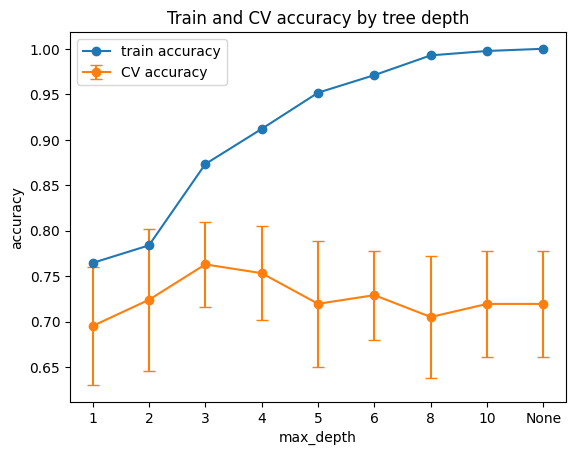

In [15]:
x = range(len(depths))
plt.errorbar(x, depth_table["train_acc"], label="train accuracy", marker="o")
plt.errorbar(x, depth_table["cv_acc"], yerr=depth_table["cv_std"], label="CV accuracy", marker="o", capsize=4)
plt.xticks(x, depth_table["max_depth"])
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Train and CV accuracy by tree depth")
plt.legend()
plt.show()

In [16]:
best_row = depth_table["cv_acc"].idxmax()
limit = depth_table.loc[best_row, "cv_acc"] - depth_table.loc[best_row, "cv_std"]
chosen_index = depth_table[depth_table["cv_acc"] >= limit].index[0]
chosen_depth = depths[chosen_index]
print("best mean CV accuracy at depth", depth_table.loc[best_row, "max_depth"])
print("limit:", round(limit, 4))
print("chosen depth:", chosen_depth)
print(depth_table.loc[max(chosen_index - 1, 0):chosen_index + 1].round(4))

best mean CV accuracy at depth 3
limit: 0.7163
chosen depth: 2
  max_depth  leaves  train_acc  cv_acc  cv_std
0         1       2     0.7645  0.6951  0.0647
1         2       4     0.7838  0.7239  0.0783
2         3       8     0.8732  0.7628  0.0466


In [17]:
rows = []
for m in [1, 2, 5, 10, 20, 40]:
    model = DecisionTreeClassifier(criterion="entropy", min_samples_leaf=m, random_state=SEED)
    s = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    leaves = model.fit(X_train, y_train).get_n_leaves()
    rows.append([m, leaves, s["train_score"].mean(), s["test_score"].mean(), s["test_score"].std()])

leaf_table = pd.DataFrame(rows, columns=["min_samples_leaf", "leaves", "train_acc", "cv_acc", "cv_std"])
print(leaf_table.round(4))

   min_samples_leaf  leaves  train_acc  cv_acc  cv_std
0                 1      33     1.0000  0.7194  0.0584
1                 2      30     0.9638  0.7292  0.0408
2                 5      19     0.9046  0.7727  0.0509
3                10      13     0.8696  0.7823  0.0447
4                20       7     0.7838  0.7239  0.0783
5                40       4     0.7645  0.6951  0.0647


In [18]:
final = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED).fit(X_train, y_train)
test_acc = final.score(X_test, y_test)
test_se = np.sqrt(test_acc * (1 - test_acc) / len(y_test))
print("test accuracy:", round(test_acc, 4), "standard error:", round(test_se, 4))

test accuracy: 0.7778 standard error: 0.0438


In [19]:
# task 4

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tree_model = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED)
deep_model = DecisionTreeClassifier(criterion="entropy", random_state=SEED)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

models = {"chosen tree": tree_model, "unlimited tree": deep_model, "logistic regression": logreg}

rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))
    rows.append([name, s["test_accuracy"].mean(), s["test_accuracy"].std(), s["test_f1"].mean()])

print(pd.DataFrame(rows, columns=["model", "acc_mean", "acc_std", "f1_mean"]).round(4))

                 model  acc_mean  acc_std  f1_mean
0          chosen tree    0.7239   0.0783   0.6726
1       unlimited tree    0.7194   0.0584   0.6822
2  logistic regression    0.8453   0.0568   0.8314


In [20]:
scaler = StandardScaler().fit(X_train)

tree_raw = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED).fit(X_train, y_train)
tree_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED).fit(scaler.transform(X_train), y_train)

same = np.mean(tree_raw.predict(X_test) == tree_scaled.predict(scaler.transform(X_test)))
print("same predictions:", same)

same predictions: 1.0


In [21]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

tree_model.fit(X_train, y_train)
logreg.fit(X_train, y_train)

for name, m in [("tree", tree_model), ("logistic regression", logreg)]:
    pred = m.predict(X_test)
    print(name)
    print("  accuracy:", round(accuracy_score(y_test, pred), 4))
    print("  f1:", round(f1_score(y_test, pred), 4))
    print(confusion_matrix(y_test, pred))

for name, m in [("tree", tree_model), ("logistic regression", logreg)]:
    a = m.score(X_test, y_test)
    print(name, "test accuracy", round(a, 4), "standard error", round(np.sqrt(a * (1 - a) / len(y_test)), 4))

tree
  accuracy: 0.7778
  f1: 0.7561
[[39  9]
 [11 31]]
logistic regression
  accuracy: 0.7889
  f1: 0.7711
[[39  9]
 [10 32]]
tree test accuracy 0.7778 standard error 0.0438
logistic regression test accuracy 0.7889 standard error 0.043


In [22]:
# task 5
from sklearn.tree import export_text

shallow = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
print(export_text(shallow, feature_names=feature_names))
ranked = sorted(zip(shallow.feature_importances_, feature_names), reverse=True)
print([(name, round(float(imp), 3)) for imp, name in ranked[:5]])

|--- thal <= 4.50
|   |--- ca <= 0.50
|   |   |--- trestbps <= 156.50
|   |   |   |--- class: 0
|   |   |--- trestbps >  156.50
|   |   |   |--- class: 1
|   |--- ca >  0.50
|   |   |--- cp <= 3.50
|   |   |   |--- class: 0
|   |   |--- cp >  3.50
|   |   |   |--- class: 1
|--- thal >  4.50
|   |--- ca <= 0.50
|   |   |--- age <= 51.50
|   |   |   |--- class: 1
|   |   |--- age >  51.50
|   |   |   |--- class: 0
|   |--- ca >  0.50
|   |   |--- cp <= 3.50
|   |   |   |--- class: 1
|   |   |--- cp >  3.50
|   |   |   |--- class: 1

[('thal', 0.363), ('ca', 0.254), ('cp', 0.174), ('trestbps', 0.13), ('age', 0.079)]


In [23]:
t = shallow.tree_
for i in range(t.node_count):
    if t.children_left[i] == -1:
        print("leaf", i, "patients:", t.n_node_samples[i], "predicts:", shallow.classes_[t.value[i].argmax()])

leaf 3 patients: 73 predicts: 0
leaf 4 patients: 4 predicts: 1
leaf 6 patients: 22 predicts: 0
leaf 7 patients: 15 predicts: 1
leaf 10 patients: 20 predicts: 1
leaf 11 patients: 22 predicts: 0
leaf 13 patients: 14 predicts: 1
leaf 14 patients: 37 predicts: 1


In [24]:
t = shallow.tree_
for i in range(t.node_count):
    l, r = t.children_left[i], t.children_right[i]
    if l != -1 and t.children_left[l] == -1 and t.children_left[r] == -1:
        if t.value[l].argmax() == t.value[r].argmax():
            print("node", i, "has two leaves with the same class:", shallow.classes_[t.value[l].argmax()])

node 12 has two leaves with the same class: 1
